<div dir="rtl">

# NextCup · חקירת נתונים (EDA)

המחברת מבצעת את התוכנית ב־`eda_plan.md`, סעיף אחרי סעיף. מתחת לכל גרף יש משפט אחד: מה רואים בו.
ההחלטות על ניקוי הנתונים כתובות בקוד ב־`features.py`, כדי שהמודל ב־M3 יראה בדיוק אותם נתונים.

</div>

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from features import DATA_FILE, build_table, load_events

# Chart style: one blue for a single series, orange only to highlight; recessive axes.
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "figure.dpi": 110,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})

raw = load_events()
df = build_table()
print(f"raw file: {len(raw):,} rows x {raw.shape[1]} columns  ->  modeling table: {len(df):,} drink events")
df.head()

raw file: 11,703 rows x 11 columns  ->  modeling table: 11,479 drink events


,person_id,recall_day,time,weekday,hour,category,item,caffeine_mg,occasion,age,sex,n_items,drinks_before,mg_before,hours_since_prev,has_next,hours_to_next
0,93705,1,09:00,Sun,9.00,coffee,"COFFEE, BREWED",348.0,breakfast,66,female,1,0,0.0,NaN,0,NaN
1,93705,2,08:00,Wed,8.00,coffee,"COFFEE, BREWED",144.0,breakfast,66,female,1,0,0.0,NaN,0,NaN
2,93708,1,12:00,Sat,12.00,coffee,"COFFEE, BREWED",24.0,lunch,66,female,1,0,0.0,NaN,0,NaN
3,93711,1,05:10,Fri,5.17,coffee,"COFFEE, BREWED",168.0,drink,56,male,1,0,0.0,NaN,1,3.33
4,93711,1,08:30,Fri,8.50,coffee,"COFFEE, BREWED",102.0,drink,56,male,1,1,168.0,3.33,1,6.00


<div dir="rtl">

## 1. השאלה ועמודת התשובה

אדם שתה עכשיו משקה עם קפאין. **האם יהיה עוד משקה היום** (`has_next`, כן/לא), ואם כן, **בעוד כמה שעות** (`hours_to_next`, מספר)?
את שתי העמודות בונים מהנתונים: מסתכלים על המשקה הבא של אותו אדם באותו יום.

</div>

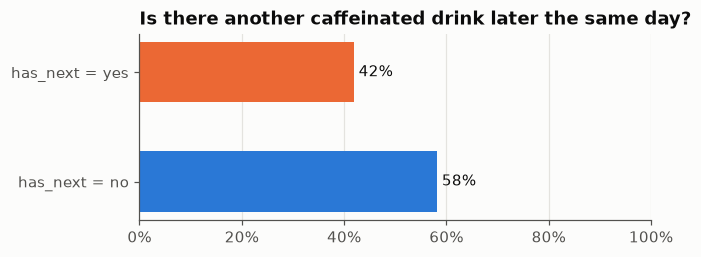

In [2]:
yes = df["has_next"].mean()
fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(["has_next = no", "has_next = yes"], [1 - yes, yes], color=[BLUE, ORANGE], height=0.55)
for i, v in enumerate([1 - yes, yes]):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", color=INK)
ax.set_xlim(0, 1); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Is there another caffeinated drink later the same day?")
plt.show()

<div dir="rtl">

**ממצא:** אחרי 42% מהמשקאות הגיע משקה נוסף באותו יום, ואחרי 58% לא. הקבוצות לא מאוזנות לגמרי, אבל אף אחת מהן לא קטנה מאוד.

</div>

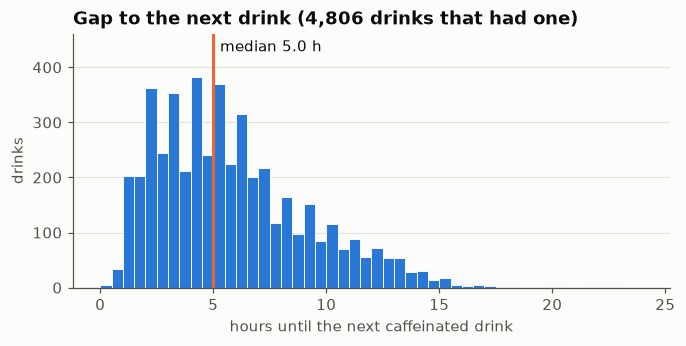

In [3]:
gap = df["hours_to_next"].dropna()
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(gap, bins=np.arange(0, 24.5, 0.5), color=BLUE, edgecolor="#fcfcfb", linewidth=0.6)
ax.axvline(gap.median(), color=ORANGE, linewidth=2)
ax.set_ylim(top=ax.get_ylim()[1] * 1.15)
ax.text(gap.median() + 0.3, ax.get_ylim()[1] * 0.93, f"median {gap.median():.1f} h", color=INK)
ax.set_xlabel("hours until the next caffeinated drink"); ax.set_ylabel("drinks")
ax.set_title(f"Gap to the next drink ({len(gap):,} drinks that had one)")
plt.show()

<div dir="rtl">

**ממצא:** החציון הוא 5 שעות, ומחצית מהפערים נופלים בין 3 ל־7.5 שעות. הקפיצות הקבועות בגרף נוצרות כי השעות מדווחות מעוגלות לחצי שעה.

</div>

<div dir="rtl">

## 2. טבלת עמודות

לכל עמודה: מה הסוג שלה, כמה ערכים שונים יש בה, ודוגמה. הסוג קובע מה מותר לחשב עליה, למשל ממוצע של ימים בשבוע הוא שטות.
הטבלה המלאה, כולל ״האם העמודה ידועה ברגע החיזוי״, נמצאת ב־`eda_plan.md`, סעיף 2.

</div>

In [4]:
kind = {
    "person_id": "id", "recall_day": "category", "weekday": "category", "time": "number (clock)",
    "hour": "number", "category": "category", "item": "category (~100 values)", "caffeine_mg": "number",
    "occasion": "category", "age": "number", "sex": "yes/no", "n_items": "number (computed)",
    "drinks_before": "number (computed)", "mg_before": "number (computed)",
    "hours_since_prev": "number (computed)", "has_next": "ANSWER yes/no", "hours_to_next": "ANSWER number",
}
pd.DataFrame({
    "kind": pd.Series(kind),
    "unique values": df.nunique(),
    "missing": df.isna().sum(),
    "example": df.iloc[1],
}).loc[list(kind)]

,kind,unique values,missing,example
person_id,id,4013,0,93705
recall_day,category,2,0,2
weekday,category,7,0,Wed
time,number (clock),195,0,08:00
hour,number,195,0,8.0
category,category,4,0,coffee
item,category (~100 values),105,0,"COFFEE, BREWED"
caffeine_mg,number,359,0,144.0
occasion,category,6,0,breakfast
age,number,63,0,66


<div dir="rtl">

**ממצא:** החוסרים היחידים הם בכוונה. `hours_since_prev` ריקה במשקה הראשון של היום, ו־`hours_to_next` ריקה כשאין משקה נוסף.

</div>

<div dir="rtl">

## 3. בדיקות איכות: חסר, כפול, שגוי

על כל בעיה מחליטים: מוחקים, משאירים, או מסמנים כחסר. כל החלטה כתובה עם הסיבה שלה ב־`eda_plan.md`, סעיף 3.

</div>

In [5]:
same_minute = raw[raw.duplicated(["person_id", "recall_day", "time"], keep=False)]
checks = pd.Series({
    "missing values in the raw file": int(raw.isna().sum().sum()),
    "exact duplicate rows": int(raw.duplicated().sum()),
    "same person, same day, same minute (groups)": same_minute.groupby(["person_id", "recall_day", "time"]).ngroups,
    "single drinks >= 1,000 mg": int((raw["caffeine_mg"] >= 1000).sum()),
    "drinks between 00:00 and 04:00": int((raw["hour"] < 4).sum()),
    "times on the half hour (%)": round(100 * (raw["hour"] * 60 % 30 == 0).mean(), 1),
    "rows before -> drink events after": f"{len(raw):,} -> {len(df):,}",
})
checks.to_frame("value")

,value
missing values in the raw file,0
exact duplicate rows,7
"same person, same day, same minute (groups)",221
"single drinks >= 1,000 mg",29
drinks between 00:00 and 04:00,116
times on the half hour (%),92.8
rows before -> drink events after,"11,703 -> 11,479"


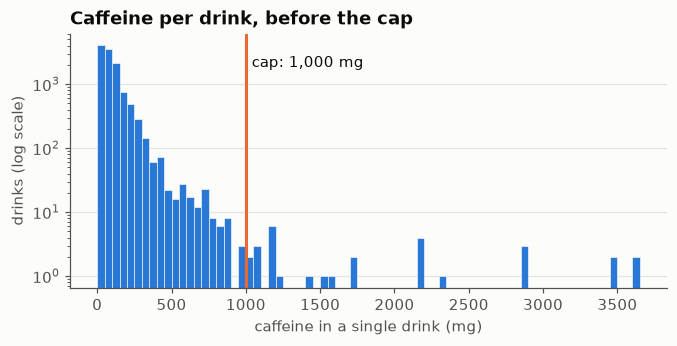

In [6]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(raw["caffeine_mg"], bins=np.arange(0, 3700, 50), color=BLUE, edgecolor="#fcfcfb", linewidth=0.4)
ax.set_yscale("log")
ax.axvline(1000, color=ORANGE, linewidth=2)
ax.text(1040, ax.get_ylim()[1] * 0.3, "cap: 1,000 mg", color=INK)
ax.set_xlabel("caffeine in a single drink (mg)"); ax.set_ylabel("drinks (log scale)")
ax.set_title("Caffeine per drink, before the cap")
plt.show()

<div dir="rtl">

**ממצא:** כמעט כל המשקאות מתחת ל־500 מ״ג, אבל יש זנב של משקאות ״אחד״ עד 3,600 מ״ג, בערך 38 כוסות קפה. השעה בשורות האלה כנראה אמיתית, והכמות לא. לכן משאירים את השורות וחותכים את הכמות ב־1,000 מ״ג.

</div>

<div dir="rtl">

## 4. התפלגויות

איך נראית כל עמודה: מה נורמלי, מה חריג, ומתי ממוצע מטעה.

</div>

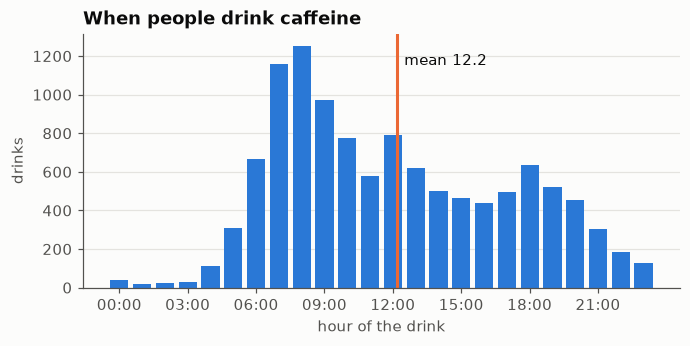

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
counts = df["hour"].astype(int).value_counts().sort_index().reindex(range(24), fill_value=0)
ax.bar(counts.index, counts.values, color=BLUE, width=0.8)
ax.axvline(df["hour"].mean(), color=ORANGE, linewidth=2)
ax.text(df["hour"].mean() + 0.3, counts.max() * 0.92, f"mean {df['hour'].mean():.1f}", color=INK)
ax.set_xticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
ax.set_xlabel("hour of the drink"); ax.set_ylabel("drinks")
ax.set_title("When people drink caffeine")
plt.show()

<div dir="rtl">

**ממצא:** השיא הגדול הוא בבוקר, בין 7:00 ל־9:00, ויש שני שיאים קטנים בצהריים (12:00) ובערב (18:00). השעה הממוצעת, בסביבות 12:10, לא מתארת אף אחד מהם: מי שמסתכל רק על הממוצע מפספס את קפה הבוקר. כאן הממוצע מטעה.

</div>

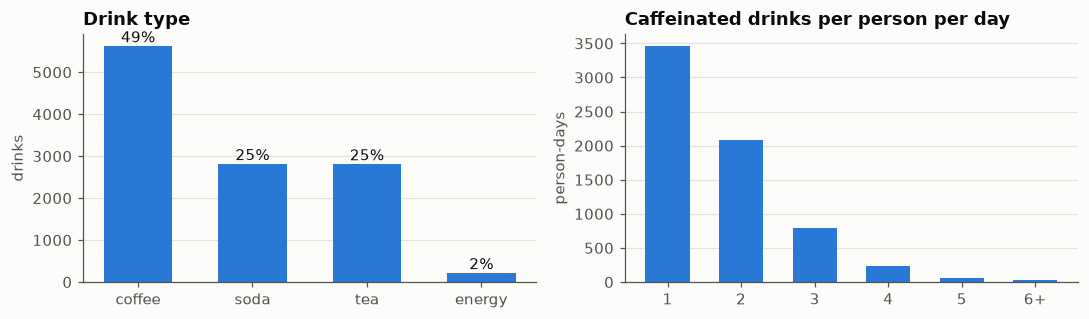

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
cat = df["category"].value_counts()
axes[0].bar(cat.index, cat.values, color=BLUE, width=0.6)
for i, v in enumerate(cat.values):
    axes[0].text(i, v, f"{v / len(df):.0%}", ha="center", va="bottom", color=INK)
axes[0].set_title("Drink type"); axes[0].set_ylabel("drinks")
per_day = df.groupby(["person_id", "recall_day"]).size().clip(upper=6).value_counts().sort_index()
axes[1].bar([str(i) if i < 6 else "6+" for i in per_day.index], per_day.values, color=BLUE, width=0.6)
axes[1].set_title("Caffeinated drinks per person per day"); axes[1].set_ylabel("person-days")
plt.tight_layout(); plt.show()

<div dir="rtl">

**ממצא:** כמחצית מהמשקאות הם קפה, ומשקאות אנרגיה הם רק 2%, קבוצה קטנה מדי כדי ללמוד עליה לבד. ברוב הימים יש משקה אחד עם קפאין או שניים. לכן ״האם יהיה עוד משקה?״ היא שאלה אמיתית ולא טריוויאלית.

</div>

<div dir="rtl">

## 5. חיפוש הסיגנל: קורלציה מול התשובה

עמודה שזזה יחד עם התשובה עוזרת לנחש אותה. עמודות מספר נבדקות בקורלציה, ועמודות קטגוריה נבדקות באחוז ה״כן״ בכל קטגוריה.
כלל אצבע מהמצגת: מעל 0.3 או מתחת למינוס 0.3 יש קשר שרואים, ובין מינוס 0.1 ל־0.1 כמעט אין קשר.

</div>

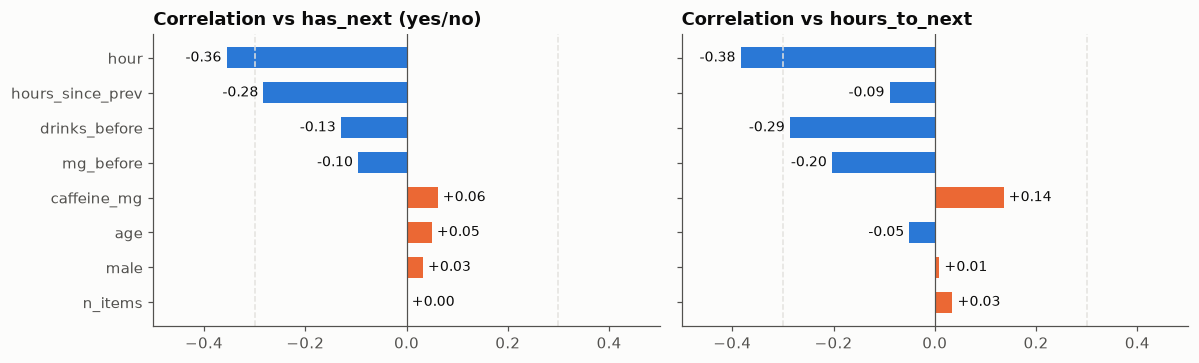

In [9]:
num = ["hour", "hours_since_prev", "drinks_before", "mg_before", "caffeine_mg", "age", "n_items"]
d = df.assign(male=(df["sex"] == "male").astype(int))
cols = num + ["male"]
corr_cls = d[cols].corrwith(d["has_next"])
had = d[d["has_next"] == 1]
corr_reg = had[cols].corrwith(had["hours_to_next"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
order = corr_cls.abs().sort_values().index
for ax, c, title in [(axes[0], corr_cls, "vs has_next (yes/no)"), (axes[1], corr_reg, "vs hours_to_next")]:
    c = c[order]
    ax.barh(c.index, c.values, color=[ORANGE if v > 0 else BLUE for v in c.values], height=0.6)
    for i, v in enumerate(c.values):
        ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:+.2f}", va="center",
                ha="left" if v >= 0 else "right", color=INK, fontsize=9)
    ax.axvline(0, color=MUTED, linewidth=0.8)
    for x in (-0.3, 0.3):
        ax.axvline(x, color=GRID, linewidth=1, linestyle="--")
    ax.set_xlim(-0.5, 0.5); ax.grid(axis="y", visible=False)
    ax.set_title(f"Correlation {title}")
plt.tight_layout(); plt.show()

<div dir="rtl">

**ממצא:** הסיגנל החזק ביותר הוא השעה: מינוס 0.36 מול ״האם יהיה עוד משקה״ ומינוס 0.38 מול ״בעוד כמה שעות״. אחריה `hours_since_prev` (מינוס 0.28) מול ״האם״, ו־`drinks_before` (מינוס 0.29) מול ״כמה״. גיל, מין וכמות הקפאין כמעט לא קשורים לתשובה (בין מינוס 0.1 ל־0.1, חוץ מ־0.14 של הכמות מול ״כמה״).

</div>

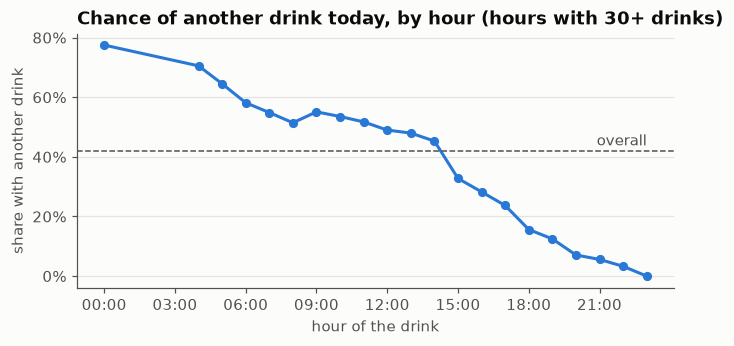

In [10]:
rate = df.groupby(df["hour"].astype(int))["has_next"].agg(["mean", "size"])
rate = rate[rate["size"] >= 30]
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(rate.index, rate["mean"], color=BLUE, linewidth=2, marker="o", markersize=5)
ax.axhline(df["has_next"].mean(), color=MUTED, linewidth=1, linestyle="--")
ax.text(23, df["has_next"].mean() + 0.02, "overall", ha="right", color=MUTED)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
ax.set_xlabel("hour of the drink"); ax.set_ylabel("share with another drink")
ax.set_title("Chance of another drink today, by hour (hours with 30+ drinks)")
plt.show()

<div dir="rtl">

**ממצא:** אחרי משקה מוקדם, לפני 6:00, יש 60%–78% סיכוי למשקה נוסף. בין 6:00 ל־14:00 הסיכוי יציב סביב 50%, ומ־15:00 הוא צונח, עד אפס ב־23:00. הקשר לא ליניארי, ולכן מודל עצים (decision tree) יתפוס אותו טוב יותר מקו ישר.

</div>

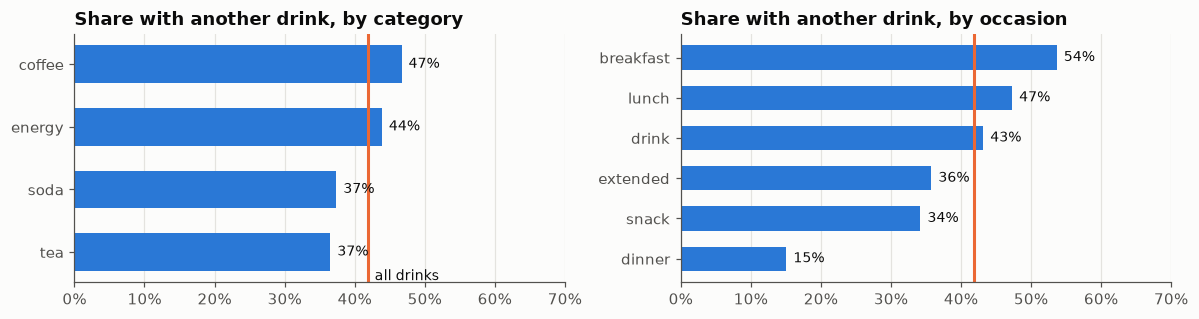

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharex=True)
base = df["has_next"].mean()
for ax, col in [(axes[0], "category"), (axes[1], "occasion")]:
    r = df.groupby(col)["has_next"].mean().sort_values()
    ax.barh(r.index, r.values, color=BLUE, height=0.6)
    for i, v in enumerate(r.values):
        ax.text(v + 0.01, i, f"{v:.0%}", va="center", color=INK, fontsize=9)
    ax.axvline(base, color=ORANGE, linewidth=2)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlim(0, 0.7); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.set_title(f"Share with another drink, by {col}")
axes[0].text(base + 0.01, -0.45, "all drinks", color=INK, fontsize=9)
plt.tight_layout(); plt.show()

<div dir="rtl">

**ממצא:** אחרי קפה (47%) יש יותר סיכוי למשקה נוסף מאשר אחרי תה או שתייה קלה (37%). ההבדל גדול עוד יותר לפי הארוחה: 54% אחרי ארוחת בוקר לעומת 15% אחרי ארוחת ערב. יום בשבוע לא משנה: כל הימים בין 41% ל־43%.

</div>

<div dir="rtl">

## 6. כל עמודה מול כל עמודה: זוגות שמספרים אותו סיפור

זוג עם קורלציה מעל 0.7 או מתחת למינוס 0.7 מסומן, ובודקים אם להשאיר את שתי העמודות. זו גם בדיקת היגיון: קשר הפוך ממה שציפינו הוא חשוד.

</div>

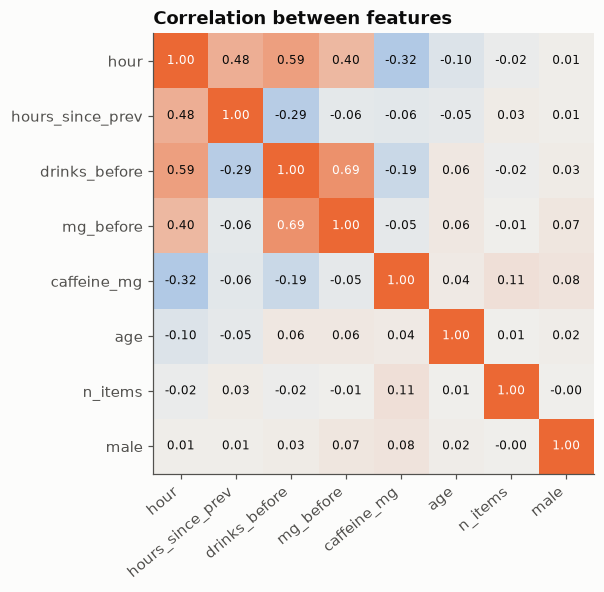

In [12]:
m = d[cols].corr()
cmap = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
fig, ax = plt.subplots(figsize=(6.5, 5.2))
ax.imshow(m, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=40, ha="right"); ax.set_yticks(range(len(cols)), cols)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color=INK if abs(m.iloc[i, j]) < 0.6 else "white")
ax.set_title("Correlation between features")
plt.show()

<div dir="rtl">

**ממצא:** אין זוג מעל 0.7. הקרוב ביותר הוא `drinks_before` מול `mg_before` (0.69), שתי עמודות שגדלות עם כל משקה. אחריו `hour` מול `drinks_before` (0.59). משאירים את שלושתן ובודקים במודל אם אחת מהן מיותרת. כל הקשרים בכיוון ההגיוני.

</div>

In [13]:
occ = df.groupby("occasion")["hour"].describe()[["25%", "50%", "75%"]].sort_values("50%")
occ.columns = ["hour 25%", "median hour", "hour 75%"]
occ

,hour 25%,median hour,hour 75%
occasion,,,
breakfast,7.0,8.0,9.0
extended,7.0,9.0,11.0
drink,8.0,12.0,16.0
lunch,12.0,13.0,14.0
snack,12.0,16.0,19.0
dinner,17.5,18.5,20.0


<div dir="rtl">

**ממצא:** הארוחה והשעה מספרות חלק מאותו סיפור: ארוחת בוקר בסביבות 8:00 וארוחת ערב בסביבות 18:30. ועדיין, `drink` ו־`snack` מפוזרות לאורך כל היום, כך ש־`occasion` מוסיפה מידע מעבר לשעה.

</div>

<div dir="rtl">

## 7. סוג המשימה, המדד, והרף שצריך לעבור

לפני שבונים מודל, מודדים כמה טוב מנחש ״מודל טיפש״. כל מודל ב־M3 צריך לעבור את הרף הזה.

</div>

In [14]:
gap = df["hours_to_next"].dropna()
by_hour = df.loc[gap.index, "hour"].astype(int)
hour_median = gap.groupby(by_hour).transform("median")
baseline = pd.Series({
    "classification: accuracy of 'always no'": f"{1 - df['has_next'].mean():.1%}",
    "classification: recall of 'always no'": "0% (never finds a next drink)",
    "regression: MAE of 'always the median (5 h)'": f"{(gap - gap.median()).abs().mean():.2f} hours",
    "regression: MAE of 'median for this hour'": f"{(gap - hour_median).abs().mean():.2f} hours",
})
baseline.to_frame("baseline")

,baseline
classification: accuracy of 'always no',58.1%
classification: recall of 'always no',0% (never finds a next drink)
regression: MAE of 'always the median (5 h)',2.60 hours
regression: MAE of 'median for this hour',2.39 hours


<div dir="rtl">

**ממצא:** מודל שאומר תמיד ״לא יהיה עוד משקה״ צודק ב־58% מהמקרים, אבל לא מוצא אף משקה נוסף. לכן בסיווג מסתכלים גם על recall ו־precision. ברגרסיה, ניחוש קבוע של 5 שעות טועה ב־2.6 שעות בממוצע, וניחוש לפי השעה בלבד טועה ב־2.4 שעות.

## סיכום: יש סיגנל?

**יש סיגנל בינוני.** שעת המשקה, הזמן מאז המשקה הקודם, מספר המשקאות עד עכשיו והארוחה זזים בבירור עם התשובה, והקשרים הגיוניים. אף עמודה לא חזקה מספיק לבדה, והזמנים מעוגלים לחצי שעה, אז צפוי שיפור מתון על פני הרף ולא חיזוי מדויק לדקה. מצד שני, אין סימן לדליפה: כל העמודות ידועות ברגע החיזוי.

</div>